# This is a sample Jupyter Notebook

Below is an example of a code cell.
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help → Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [60]:
%load_ext autoreload
%autoreload 2
# these make it so that if you change the files you import you won't need to restart the Jupyter Notebook kernel

from analytic_formulation import Q_

# --- Params ---
params = {
    'rd':      Q_(0.316, 'm'),
    'nP':      Q_(4000, 'rpm'),
    'a':       1.2,
    'b':       1.0,
    'c':       0.5,
    'PP':      Q_(100.0, 'kW'),
    'mv':      Q_(1500.0, 'kg'),
    'g':       Q_(9.81, 'm/s**2'),
    'fr':      0.015,                    # plain float, avoids pint friction
    'rho_a':   Q_(1.225, 'kg/m**3'),
    'CD':      0.30,                     # plain float
    'Af':      Q_(2.2, 'm**2'),
    'gamma_m': 1.05,                     # plain float
    'eta_T':   0.92,                     # plain float
    'eta_o':   0.38,
    'HL':      Q_(44e6, 'J/kg'),
}



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload





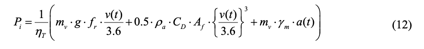

In [61]:
from scipy.optimize import minimize, Bounds, NonlinearConstraint
from analytic_formulation import OlengEquations, Q_
import numpy as np

# --- Optimization Setup ---
delta_s    = Q_(500.0, 'm')
total_dist = Q_(10_000.0, 'm')
n_steps    = int(total_dist / delta_s)

v_cruise = Q_(90, 'km/h').to('m/s')
v_max = Q_(120, 'km/h').to('m/s')
a_max = 4.0  # m/s²

def make_model():
    """Create a fresh model for each evaluation to ensure consistency."""
    return OlengEquations(params, initial_velocity=v_cruise)

def fuel_objective(acceleration_profile):
    """Objective: minimize total fuel consumption.
    Includes error handling for infeasible profiles.
    """
    try:
        model = make_model()
        results = model.run(acceleration_profile, delta_s, xi_ax=3.9)
        fuel = float(results['fuel_cumulative_kg'].iloc[-1])
        # Penalize invalid results
        if fuel < 0 or np.isnan(fuel) or np.isinf(fuel):
            return 1e10
        return fuel
    except (ValueError, RuntimeError):
        # If simulation fails, return large penalty
        return 1e10

def speed_constraint(acceleration_profile):
    """Constraint: velocity must not exceed v_max at any segment.
    Returns v_max - velocity at each step (must be >= 0).
    Includes error handling for infeasible profiles.
    """
    try:
        model = make_model()
        results = model.run(acceleration_profile, delta_s, xi_ax=3.9)
        # Skip row 0 (initial state) and check all subsequent velocities
        speeds = results['velocity_ms'].iloc[1:].to_numpy()
        return v_max.to('m/s').magnitude - speeds
    except (ValueError, RuntimeError):
        # If simulation fails, return zeros (will violate constraint)
        return np.zeros(len(acceleration_profile))

# Bounds on acceleration: -4 to +4 m/s² (allows braking)
bounds = Bounds([-a_max] * n_steps, [a_max] * n_steps)

# Nonlinear constraint: speed <= v_max everywhere
constraints = [
    NonlinearConstraint(speed_constraint, 0.0, np.inf)
]

initial_guess = np.zeros(n_steps)

# Run optimization
print("Starting optimization...")
minimization = minimize(
    fuel_objective,
    initial_guess,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints,
    options={'maxiter': 100, 'ftol': 1e-6}
)

print("\n✓ Optimization complete!")
print(f"  Success: {minimization.success}")
print(f"  Message: {minimization.message}")
print(f"  Optimal fuel: {minimization.fun:.6f} kg")
print(f"  Iterations: {minimization.nit}")

# Verify constraints are satisfied
final_results = make_model().run(minimization.x, delta_s, xi_ax=3.9)
max_speed = final_results['velocity_kmh'].max()
max_accel = np.abs(minimization.x).max()
print(f"\n✓ Constraints verified:")
print(f"  Max speed: {max_speed:.2f} km/h (limit: 120 km/h)")
print(f"  Max |acceleration|: {max_accel:.3f} m/s² (limit: {a_max} m/s²)")


Starting optimization...

✓ Optimization complete!
  Success: True
  Message: Optimization terminated successfully
  Optimal fuel: 0.163406 kg
  Iterations: 22

✓ Constraints verified:
  Max speed: 119.46 km/h (limit: 120 km/h)
  Max |acceleration|: 0.152 m/s² (limit: 4.0 m/s²)


Optimal acceleration profile (m/s²):
[ 0.15155127  0.1271589   0.09651521  0.06546742  0.03155649  0.00255581
  0.00029425 -0.00229148 -0.00187407 -0.00085545 -0.00054942  0.00049103
  0.00142904  0.00213814  0.00247997 -0.00970221 -0.05111056 -0.08601029
 -0.11890152 -0.14539134]
Total fuel: 0.1634057283 kg


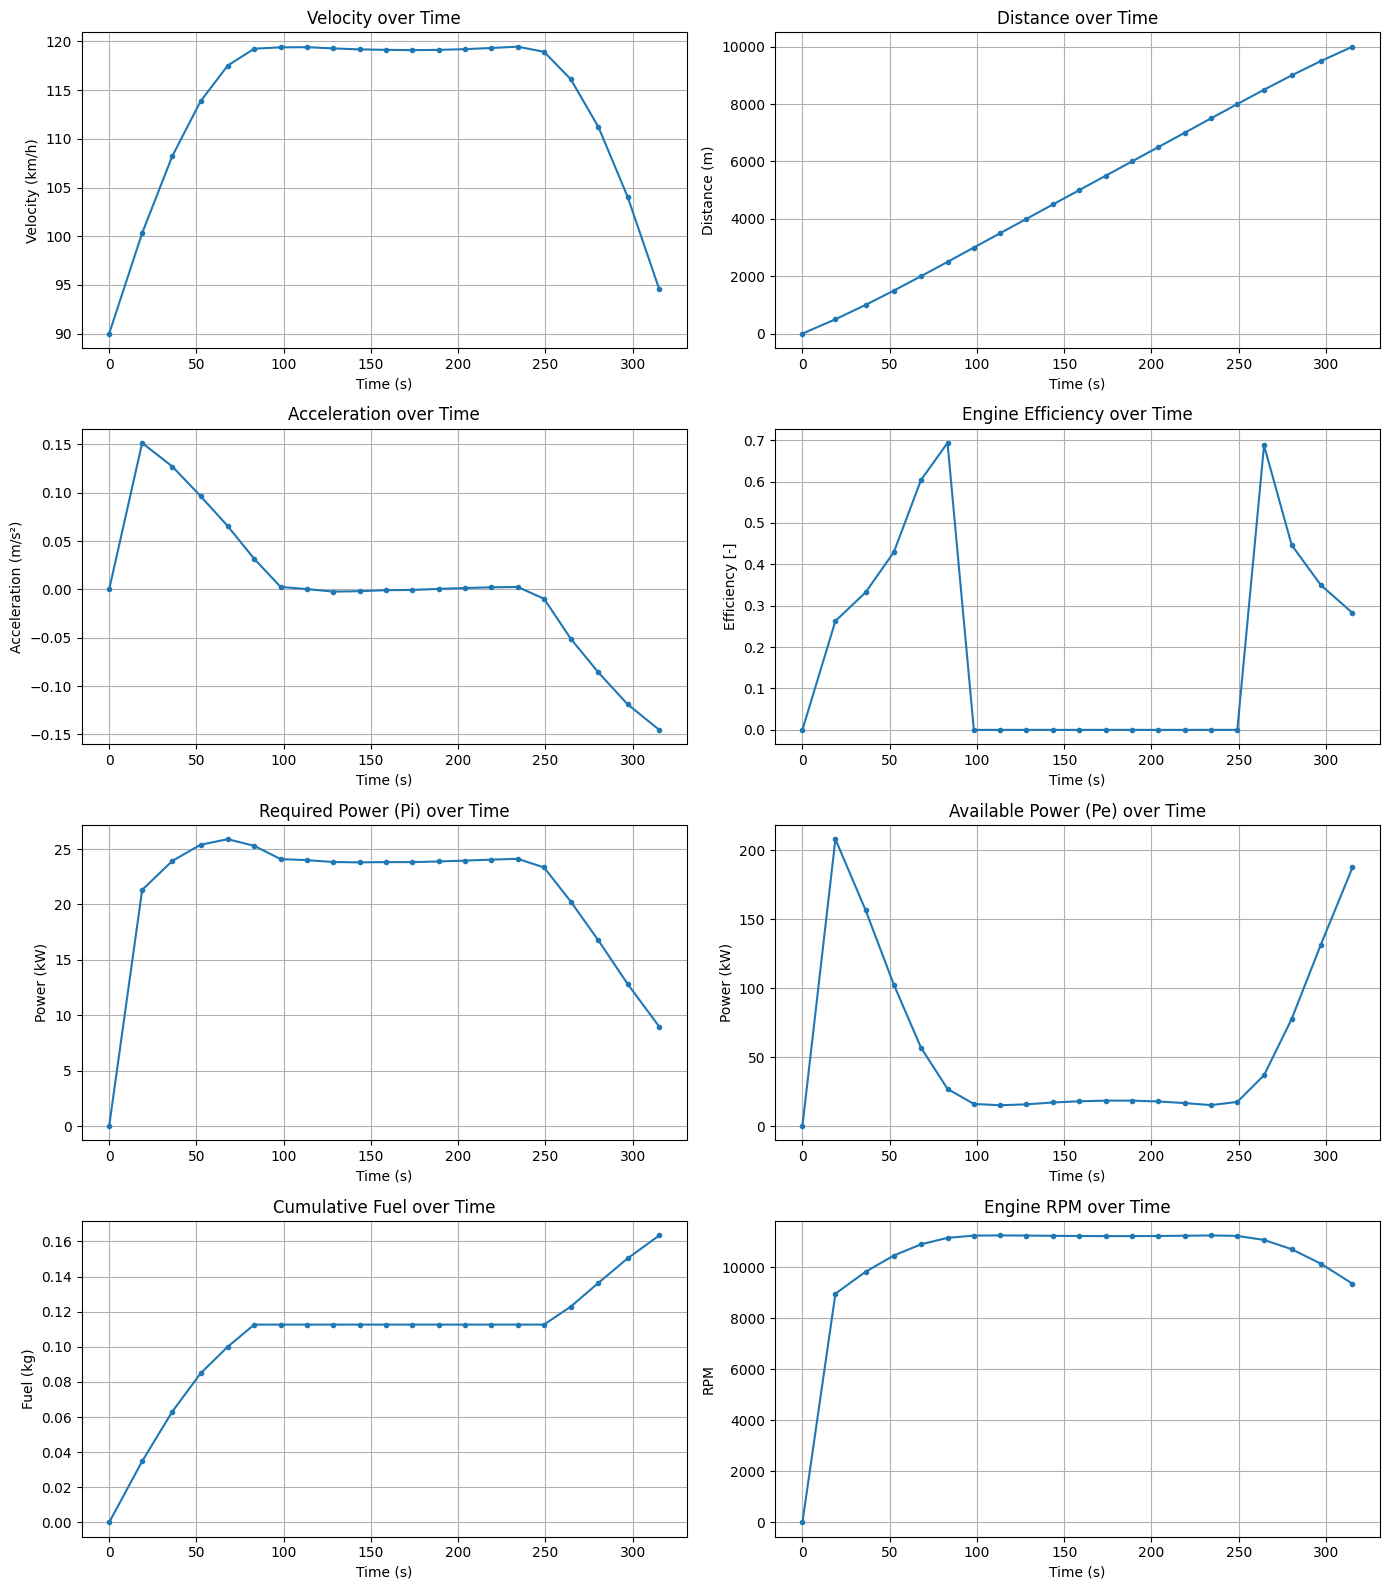


✓ Results saved to results.csv


In [62]:
import matplotlib.pyplot as plt

# Use the final results from the optimization
results = final_results

print("Optimal acceleration profile (m/s²):")
print(minimization.x)
print(f"Total fuel: {results['fuel_cumulative_kg'].iloc[-1]:.10f} kg")

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

plots = [
    ('time_s', 'velocity_ms',          'Time (s)', 'Velocity (km/h)',       'Velocity over Time'),
    ('time_s', 'distance_m',           'Time (s)', 'Distance (m)',          'Distance over Time'),
    ('time_s', 'acceleration_ms2',     'Time (s)', 'Acceleration (m/s²)',   'Acceleration over Time'),
    ('time_s', 'efficiency',           'Time (s)', 'Efficiency [-]',        'Engine Efficiency over Time'),
    ('time_s', 'Pi_kW',               'Time (s)', 'Power (kW)',            'Required Power (Pi) over Time'),
    ('time_s', 'Pe_kW',               'Time (s)', 'Power (kW)',            'Available Power (Pe) over Time'),
    ('time_s', 'fuel_cumulative_kg',   'Time (s)', 'Fuel (kg)',             'Cumulative Fuel over Time'),
    ('time_s', 'engine_rpm',           'Time (s)', 'RPM',                   'Engine RPM over Time'),
]

for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, plots):
    y_data = results[y_col] * 3.6 if y_col == 'velocity_ms' else results[y_col]
    ax.plot(results[x_col], y_data, marker='o', markersize=3)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

# Also save results to CSV
results.to_csv("results.csv", index=False)
print("\n✓ Results saved to results.csv")